In [6]:
import sys
import flwr
import torch

print("Python path:", sys.executable)
print("PyTorch version:", torch.__version__)
print("Flower version:", flwr.__version__)

Python path: /home/angelo/H.IAAC/implementations/.venv/bin/python
PyTorch version: 2.15.0+cu132
Flower version: 1.43.0


Estudo comparativo de tecnicas de seleção de clientes em ambiente federado, para reconstrução e classificação de imagens usando o dataset CIFAR - 100

Prerequisitos e Setup de Ambiente Virtual:

-Python 3.10, 3.11 ou 2.12

Crie um ambiente virtual:

Linux (bash): 
    python3 -m venv .venv
    source .venv/bin/activate

Instale dependências (bash):
    pip install --upgrade pip
    pip install torch torchvision
    pip install "flwr[simulation]" "flwr-datasets[vision]" ipykernel ipywidgets

Registrar o Kernel (bash):
    python -m ipykernel install --user --name=fl-cifar100 --display-name "Python (FL CIFAR-100)"

In [14]:
import os
import gc
import ray
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import CIFAR100
from torchvision.transforms import Compose, Normalize, ToTensor

import flwr as fl
from flwr.client import NumPyClient, ClientApp
from flwr.common import FitIns, Context, ndarrays_to_parameters, parameters_to_ndarrays
from flwr.server import ServerApp, ServerAppComponents, ServerConfig
from flwr.server.strategy import FedAvg, FedProx, FedYogi
from flwr_datasets import FederatedDataset
from flwr_datasets.partitioner import DirichletPartitioner

Definição do modelo e do dataset selecionado (CIFAR-100 usando uma CNN) 

In [15]:
class SimpleNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(64 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 100)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

def train_with_metrics(net, train_loader, epochs=1, device="cpu", proximal_mu=0.0, global_params=None):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(net.parameters(), lr=0.01, momentum=0.9)
    net.to(device)
    net.train()

    global_tensors = None
    if proximal_mu > 0.0 and global_params is not None:
        global_tensors = [torch.tensor(p, device=device) for p in global_params]

    total_loss, correct, total_samples, local_steps = 0.0, 0, 0, 0

    for _ in range(epochs):
        for images, labels in train_loader:  # <-- Native PyTorch tuple unpacking (Zero copy overhead)
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = net(images)
            loss = criterion(outputs, labels)

            if global_tensors is not None:
                proximal_term = 0.0
                for local_w, global_w in zip(net.parameters(), global_tensors):
                    proximal_term += (local_w - global_w).norm(2) ** 2
                loss += (proximal_mu / 2.0) * proximal_term

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * labels.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct += (predicted == labels).sum().item()
            local_steps += 1

    return total_loss / total_samples, correct / total_samples, local_steps


def test(net, test_loader, device="cpu"):
    criterion = nn.CrossEntropyLoss()
    correct, total, loss = 0, 0, 0.0
    net.to(device)
    net.eval()
    with torch.no_grad():
        for images, labels in test_loader:  # <-- Native PyTorch tuple unpacking
            images, labels = images.to(device), labels.to(device)
            outputs = net(images)
            loss += criterion(outputs, labels).item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return loss / len(test_loader), correct / total

Definição do Cliente do flower

In [16]:
class FlowerClient(NumPyClient):
    def __init__(self, net, train_loader, device):
        self.net = net
        self.train_loader = train_loader
        self.device = device

    def get_parameters(self, config):
        return [val.cpu().numpy() for _, val in self.net.state_dict().items()]

    def set_parameters(self, parameters):
        params_dict = zip(self.net.state_dict().keys(), parameters)
        state_dict = {k: torch.tensor(v) for k, v in params_dict}
        self.net.load_state_dict(state_dict, strict=True)

    def fit(self, parameters, config):
        self.set_parameters(parameters)
        proximal_mu = config.get("proximal_mu", 0.0)
        train_loss, train_acc, local_steps = train_with_metrics(
            self.net,
            self.train_loader,
            epochs=1,
            device=self.device,
            proximal_mu=proximal_mu,
            global_params=parameters,
        )
        metrics = {
            "train_loss": float(train_loss),
            "train_accuracy": float(train_acc),  # Fixed: matches key read by strategy
            "local_steps": int(local_steps),
        }
        return self.get_parameters(config={}), len(self.train_loader.dataset), metrics

Definição das estrategias de seleção de clientes e estrategias de agregação

In [17]:
class CustomSelectionMix:
    def __init__(self, selection_mode="random", *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.selection_mode = selection_mode
        self.client_metrics = {}
        self.rr_index = 0

    def configure_fit(self, server_round: int, parameters, client_manager):
        sample_size, min_num_clients = self.num_fit_clients(client_manager.num_available())
        all_clients = list(client_manager.all().values())

        if len(all_clients) < min_num_clients:
            return []

        all_clients.sort(key=lambda c: int(c.cid))

        if self.selection_mode == "random":
            selected_clients = random.sample(all_clients, sample_size)

        elif self.selection_mode == "round_robin":
            selected_clients = []
            for _ in range(sample_size):
                selected_clients.append(all_clients[self.rr_index % len(all_clients)])
                self.rr_index += 1

        elif self.selection_mode == "highest_loss":
            selected_clients = sorted(
                all_clients,
                key=lambda c: self.client_metrics.get(c.cid, {}).get("loss", float("inf")),
                reverse=True,
            )[:sample_size]

        elif self.selection_mode == "lowest_accuracy":
            selected_clients = sorted(
                all_clients,
                key=lambda c: self.client_metrics.get(c.cid, {}).get("accuracy", -1.0),
                reverse=False,
            )[:sample_size]

        else:
            raise ValueError(f"Unknown selection mode: {self.selection_mode}")

        config = self.on_fit_config_fn(server_round) if self.on_fit_config_fn else {}
        fit_ins = FitIns(parameters, config)
        return [(client, fit_ins) for client in selected_clients]

    def aggregate_fit(self, server_round, results, failures):  # Fixed: double 'g'
        for client_proxy, fit_res in results:
            if fit_res.metrics:
                self.client_metrics[client_proxy.cid] = {
                    "loss": fit_res.metrics.get("train_loss", float("inf")),
                    "accuracy": fit_res.metrics.get("train_accuracy", 0.0),
                }
        return super().aggregate_fit(server_round, results, failures)


class CustomFedAvg(CustomSelectionMix, FedAvg):
    pass


class CustomFedProx(CustomSelectionMix, FedProx):
    pass


class CustomFedYogi(CustomSelectionMix, FedYogi):
    pass


class CustomFedNova(CustomSelectionMix, FedAvg):
    def aggregate_fit(self, server_round, results, failures):  # Fixed: double 'g'
        for client_proxy, fit_res in results:
            if fit_res.metrics:
                self.client_metrics[client_proxy.cid] = {
                    "loss": fit_res.metrics.get("train_loss", float("inf")),
                    "accuracy": fit_res.metrics.get("train_accuracy", 0.0),
                }
        if not results:
            return None, {}

        global_weights = parameters_to_ndarrays(self.current_parameters)
        total_samples = sum(fit_res.num_examples for _, fit_res in results)
        weighted_taus = 0.0
        normalized_deltas = [np.zeros_like(w) for w in global_weights]

        for _, fit_res in results:
            client_weights = parameters_to_ndarrays(fit_res.parameters)
            tau_i = fit_res.metrics.get("local_steps", 1)
            p_i = fit_res.num_examples / total_samples
            weighted_taus += p_i * tau_i

            for idx, (w_glob, w_cli) in enumerate(zip(global_weights, client_weights)):
                normalized_deltas[idx] += p_i * ((w_cli - w_glob) / tau_i)

        new_weights = [
            w_glob + weighted_taus * delta
            for w_glob, delta in zip(global_weights, normalized_deltas)
        ]
        self.current_parameters = ndarrays_to_parameters(new_weights)
        return self.current_parameters, {}

Definição do ciclo de treinamento, e abordagem de varios ciclos de treinamento atraves de varios valores de aplha (parametro do distribuidor de dirichilet) para verificar como abordagens diferentes de seleção de agregação de clientes respondem a datasets fortemente iid assim como não-iid, verificando como as metricas variam ao ponto que os clientes ficam cada vez mais estatisticamente diferentes. Foram utlizidas 4 tecnicas de agregação: FedAvg, FedProx, FedYogi e FedNova, além disso tambem foram utilizadas 4 formas de seleção de de clientes combinadas com as formas de agregação, eleas foram, Round robin, por pior acurracia, por pior loss.

In [ ]:
os.environ["RAY_memory_monitor_refresh_ms"] = "0"

NUM_CLIENTS = 20
NUM_ROUNDS = 30
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TOTAL_CPUS = os.cpu_count() or 4

alphas = [0.1] # Pode ser variado entre qualquer valor entre 0 e +inf
aggregators = ["fedyogi"] # existem 4 agregadores suportados, fedavg, fedyogi, fedprox e fedNova
selectors = ["round_robin", "highest_loss", "lowest_accuracy"] # tres metodos de seleção especificos

all_results = {}

pytorch_transforms = Compose([
    ToTensor(),
    Normalize(mean=(0.5071, 0.4867, 0.4408), std=(0.2675, 0.2565, 0.2761)),
])

def get_initial_parameters():
    net = SimpleNet()
    return ndarrays_to_parameters([val.cpu().numpy() for _, val in net.state_dict().items()])

def split_dirichlet_indices(targets, num_clients, alpha, seed=42):
    rng = np.random.default_rng(seed)
    targets = np.array(targets)
    num_classes = len(np.unique(targets))
    client_indices = [[] for _ in range(num_clients)]

    for k in range(num_classes):
        idx_k = np.where(targets == k)[0]
        rng.shuffle(idx_k)
        proportions = rng.dirichlet(np.repeat(alpha, num_clients))
        proportions = np.array([p * (len(idx_j) < len(targets) / num_clients) for p, idx_j in zip(proportions, client_indices)])
        proportions = proportions / proportions.sum()
        splits = (np.cumsum(proportions) * len(idx_k)).astype(int)[:-1]
        for cid, idx_split in enumerate(np.split(idx_k, splits)):
            client_indices[cid].extend(idx_split.tolist())

    return client_indices


print("Carregando CIFAR-100 localmente via torchvision...")
train_dataset = CIFAR100(root="./data", train=True, download=True, transform=pytorch_transforms)
test_dataset = CIFAR100(root="./data", train=False, download=True, transform=pytorch_transforms)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
print("Dataset pronto!")


for alpha in alphas:
    print(f"\n=============== Ciclo de Treinamento com Alpha = {alpha} ==================")

    client_id_to_indices = split_dirichlet_indices(train_dataset.targets, NUM_CLIENTS, alpha)

    def client_fn(context: Context):
        cid = int(context.node_config["partition-id"])
        subset = Subset(train_dataset, client_id_to_indices[cid])
        train_loader = DataLoader(subset, batch_size=32, shuffle=True)
        return FlowerClient(SimpleNet(), train_loader, DEVICE).to_client()

    client_app = ClientApp(client_fn=client_fn)

    for agg in aggregators:
        for sel in selectors:
            print(f"\n --- Treinando: Alpha = {alpha} | Sistema de Agregação = {agg.upper()} | Seletor = {sel.upper()} ---")

            tracker = {"latest_acc": 0.0}

            def evaluate_fn(server_round, parameters, config):
                net = SimpleNet()
                params_dict = zip(net.state_dict().keys(), parameters)
                state_dict = {k: torch.tensor(v) for k, v in params_dict}
                net.load_state_dict(state_dict, strict=True)
                loss, accuracy = test(net, test_loader, device=DEVICE)
                tracker["latest_acc"] = accuracy
                return loss, {"accuracy": accuracy}

            init_params = get_initial_parameters()
            common_args = {
                "selection_mode": sel,
                "fraction_fit": 0.4,
                "min_fit_clients": 4,
                "fraction_evaluate": 0.0,
                "min_available_clients": NUM_CLIENTS,
                "evaluate_fn": evaluate_fn,
                "initial_parameters": init_params,
            }

            if agg == "fedavg":
                strategy = CustomFedAvg(**common_args)
            elif agg == "fedprox":
                strategy = CustomFedProx(**common_args, proximal_mu=0.5)
            elif agg == "fedyogi":
                strategy = CustomFedYogi(
                    **common_args, eta=1e-2, eta_l=1e-2, beta_1=0.9, beta_2=0.99, tau=1e-3
                )
            elif agg == "fednova":
                strategy = CustomFedNova(**common_args)
                strategy.current_parameters = init_params

            def server_fn(context: Context):
                config = ServerConfig(num_rounds=NUM_ROUNDS)
                return ServerAppComponents(strategy=strategy, config=config)

            server_app = ServerApp(server_fn=server_fn)

            if ray.is_initialized():
                ray.shutdown()
            gc.collect()

            fl.simulation.run_simulation(
                server_app=server_app,
                client_app=client_app,
                num_supernodes=NUM_CLIENTS,
                backend_config={
                    "client_resources": {
                        "num_cpus": TOTAL_CPUS,
                        "num_gpus": 1.0 if torch.cuda.is_available() else 0,
                    },
                    "init_args": {
                        "num_cpus": TOTAL_CPUS,
                        "object_store_memory": 200 * 1024 * 1024,  # 200 MB object store
                        "include_dashboard": False,                # Saves ~300 MB of RAM
                    },
                },
            )

            if ray.is_initialized():
                ray.shutdown()
            gc.collect()

            final_acc = tracker["latest_acc"]
            all_results[(alpha, agg, sel)] = final_acc
            print(f"Resultado -> Alpha: {alpha} | {agg} + {sel} = {final_acc * 100:.2f}%")


print("\n==================== Resumo Experimental ====================")
print(f"{'Alpha':<8} | {'Agregador':<10} | {'Seletor':<16} | {'Acuracia':<15}")
print("-" * 58)
for (a, agg, sel), acc in all_results.items():
    print(f"{a:<8} | {agg:<10} | {sel:<16} | {acc * 100:.2f}%")

Carregando CIFAR-100 localmente via torchvision...
Dataset pronto!

=============== Ciclo de Treinamento com Alpha = 0.1 ==================

 --- Treinando: Alpha = 0.1 | Sistema de Agregação = FEDYOGI | Seletor = ROUND_ROBIN ---



            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower ServerApp, config: num_rounds=30, no round_timeout
INFO :      
INFO :      [INIT]
INFO :      Using initial global parameters provided by strategy
INFO :      Starting evaluation of initial global parameters
INFO :      initial parameters (loss, other metrics): 4.605838696668102, {'accuracy': 0.0108}
INFO :      
INFO :      [ROUND 1]
INFO :      configure_fit: strategy sampled 8 clients (out of 20)
/home/angelo/H.IAAC/implementations/.venv/lib/python3.14/site-packages/ray/_private/worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(
INFO :      aggregate_fit: received 8 results and 0 failures
INFO :      fit p

Resultado -> Alpha: 0.1 | fedyogi + round_robin = 32.82%

 --- Treinando: Alpha = 0.1 | Sistema de Agregação = FEDYOGI | Seletor = HIGHEST_LOSS ---



            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower ServerApp, config: num_rounds=30, no round_timeout
INFO :      
INFO :      [INIT]
INFO :      Using initial global parameters provided by strategy
INFO :      Starting evaluation of initial global parameters
INFO :      initial parameters (loss, other metrics): 4.605231701188786, {'accuracy': 0.0102}
INFO :      
INFO :      [ROUND 1]
INFO :      configure_fit: strategy sampled 8 clients (out of 20)
INFO :      aggregate_fit: received 8 results and 0 failures
INFO :      fit progress: (1, 4.555943738123414, {'accuracy': 0.0305}, 26.57046032700009)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 8 clients (out of 20)
INFO :      aggregate_fit: received 8 results and 0 failures
INFO :      fit progress: (2, 4.385062056741897, {'accuracy'

Resultado -> Alpha: 0.1 | fedyogi + highest_loss = 32.91%

 --- Treinando: Alpha = 0.1 | Sistema de Agregação = FEDYOGI | Seletor = LOWEST_ACCURACY ---



            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower ServerApp, config: num_rounds=30, no round_timeout
INFO :      
INFO :      [INIT]
INFO :      Using initial global parameters provided by strategy
INFO :      Starting evaluation of initial global parameters
INFO :      initial parameters (loss, other metrics): 4.607105895971796, {'accuracy': 0.0104}
INFO :      
INFO :      [ROUND 1]
INFO :      configure_fit: strategy sampled 8 clients (out of 20)
INFO :      aggregate_fit: received 8 results and 0 failures
INFO :      fit progress: (1, 4.565743658952652, {'accuracy': 0.0267}, 26.063806982000187)
INFO :      configure_evaluate: no clients selected, skipping evaluation
INFO :      
INFO :      [ROUND 2]
INFO :      configure_fit: strategy sampled 8 clients (out of 20)
INFO :      aggregate_fit: received 8 results and 0 failures
INFO :      fit progress: (2, 4.417561758855346, {'accuracy

Resultado -> Alpha: 0.1 | fedyogi + lowest_accuracy = 32.73%

==================== Resumo Experimental ====================
Alpha    | Agregador  | Seletor          | Acuracia       
----------------------------------------------------------
0.1      | fedyogi    | round_robin      | 32.82%
0.1      | fedyogi    | highest_loss     | 32.91%
0.1      | fedyogi    | lowest_accuracy  | 32.73%


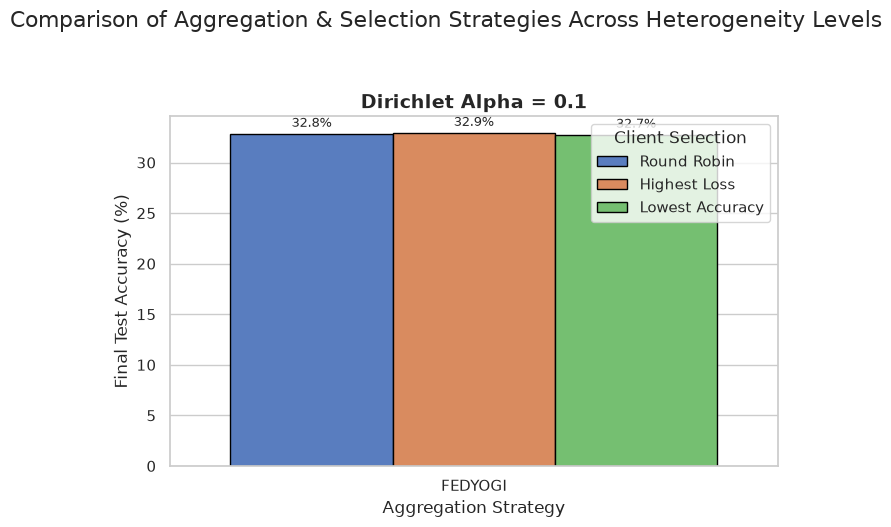

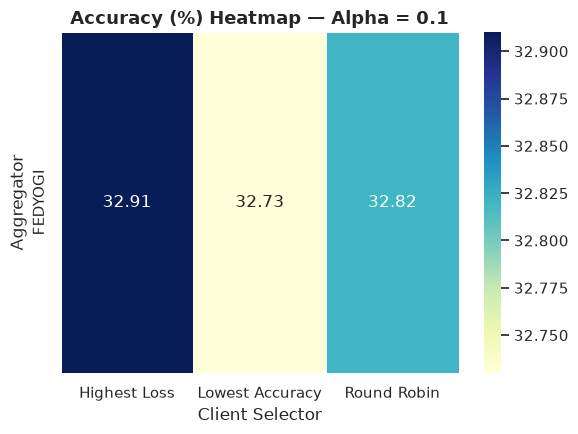

In [18]:
if "all_results" not in globals() or not all_results:
    if os.path.exists("fl_benchmark_results.pkl"):
        with open("fl_benchmark_results.pkl", "rb") as f:
            all_results = pickle.load(f)
    else:
        raise RuntimeError("No results found! Please run Cells 1-4 first to train and generate 'all_results'.")

rows = []
for (alpha, agg, sel), acc in all_results.items():
    rows.append({
        "Alpha": alpha,
        "Aggregator": agg.upper(),
        "Selector": sel.replace("_", " ").title(),
        "Accuracy (%)": acc * 100
    })

df_results = pd.DataFrame(rows)

sns.set_theme(style="whitegrid", palette="muted")
unique_alphas = sorted(df_results["Alpha"].unique(), reverse=True)

fig, axes = plt.subplots(1, len(unique_alphas), figsize=(7 * len(unique_alphas), 5), sharey=True)
if len(unique_alphas) == 1:
    axes = [axes]

for ax, alpha in zip(axes, unique_alphas):
    subset = df_results[df_results["Alpha"] == alpha]
    sns.barplot(
        data=subset,
        x="Aggregator",
        y="Accuracy (%)",
        hue="Selector",
        ax=ax,
        edgecolor="black"
    )
    ax.set_title(f"Dirichlet Alpha = {alpha}", fontsize=14, fontweight="bold")
    ax.set_xlabel("Aggregation Strategy", fontsize=12)
    ax.set_ylabel("Final Test Accuracy (%)" if ax == axes[0] else "")
    ax.legend(title="Client Selection", loc="upper right")
    
    # Add exact percentage labels on top of bars
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9)

plt.suptitle("Comparison of Aggregation & Selection Strategies Across Heterogeneity Levels", fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, len(unique_alphas), figsize=(6 * len(unique_alphas), 4.5))
if len(unique_alphas) == 1:
    axes = [axes]

for ax, alpha in zip(axes, unique_alphas):
    subset = df_results[df_results["Alpha"] == alpha]
    pivot_table = subset.pivot(index="Aggregator", columns="Selector", values="Accuracy (%)")
    
    sns.heatmap(
        pivot_table,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        cbar=(ax == axes[-1]),
        ax=ax,
        linewidths=0.5
    )
    ax.set_title(f"Accuracy (%) Heatmap — Alpha = {alpha}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Client Selector")
    ax.set_ylabel("Aggregator" if ax == axes[0] else "")

plt.tight_layout()
plt.show()